In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("/content/ai_student_impact_dataset (1).csv")

In [3]:
df.head()

,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58,Medium
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00,Medium


In [4]:
df=df.drop(columns=['Student_ID'])

In [5]:
df.shape

(17790, 15)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17790 entries, 0 to 17789
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Major_Category              17790 non-null  object 
 1   Year_of_Study               17790 non-null  object 
 2   Pre_Semester_GPA            17790 non-null  float64
 3   Weekly_GenAI_Hours          17790 non-null  float64
 4   Primary_Use_Case            17790 non-null  object 
 5   Prompt_Engineering_Skill    17790 non-null  object 
 6   Tool_Diversity              17790 non-null  int64  
 7   Paid_Subscription           17790 non-null  bool   
 8   Traditional_Study_Hours     17790 non-null  float64
 9   Perceived_AI_Dependency     17790 non-null  int64  
 10  Institutional_Policy        17790 non-null  object 
 11  Anxiety_Level_During_Exams  17790 non-null  int64  
 12  Post_Semester_GPA           17790 non-null  float64
 13  Skill_Retention_Score       177

In [7]:
df.isnull().sum()

,0
Major_Category,0
Year_of_Study,0
Pre_Semester_GPA,0
Weekly_GenAI_Hours,0
Primary_Use_Case,0
Prompt_Engineering_Skill,0
Tool_Diversity,0
Paid_Subscription,0
Traditional_Study_Hours,0
Perceived_AI_Dependency,0


# **EDA**

/tmp/ipykernel_2369/116080789.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Perceived_AI_Dependency', y='Skill_Retention_Score', palette='viridis')


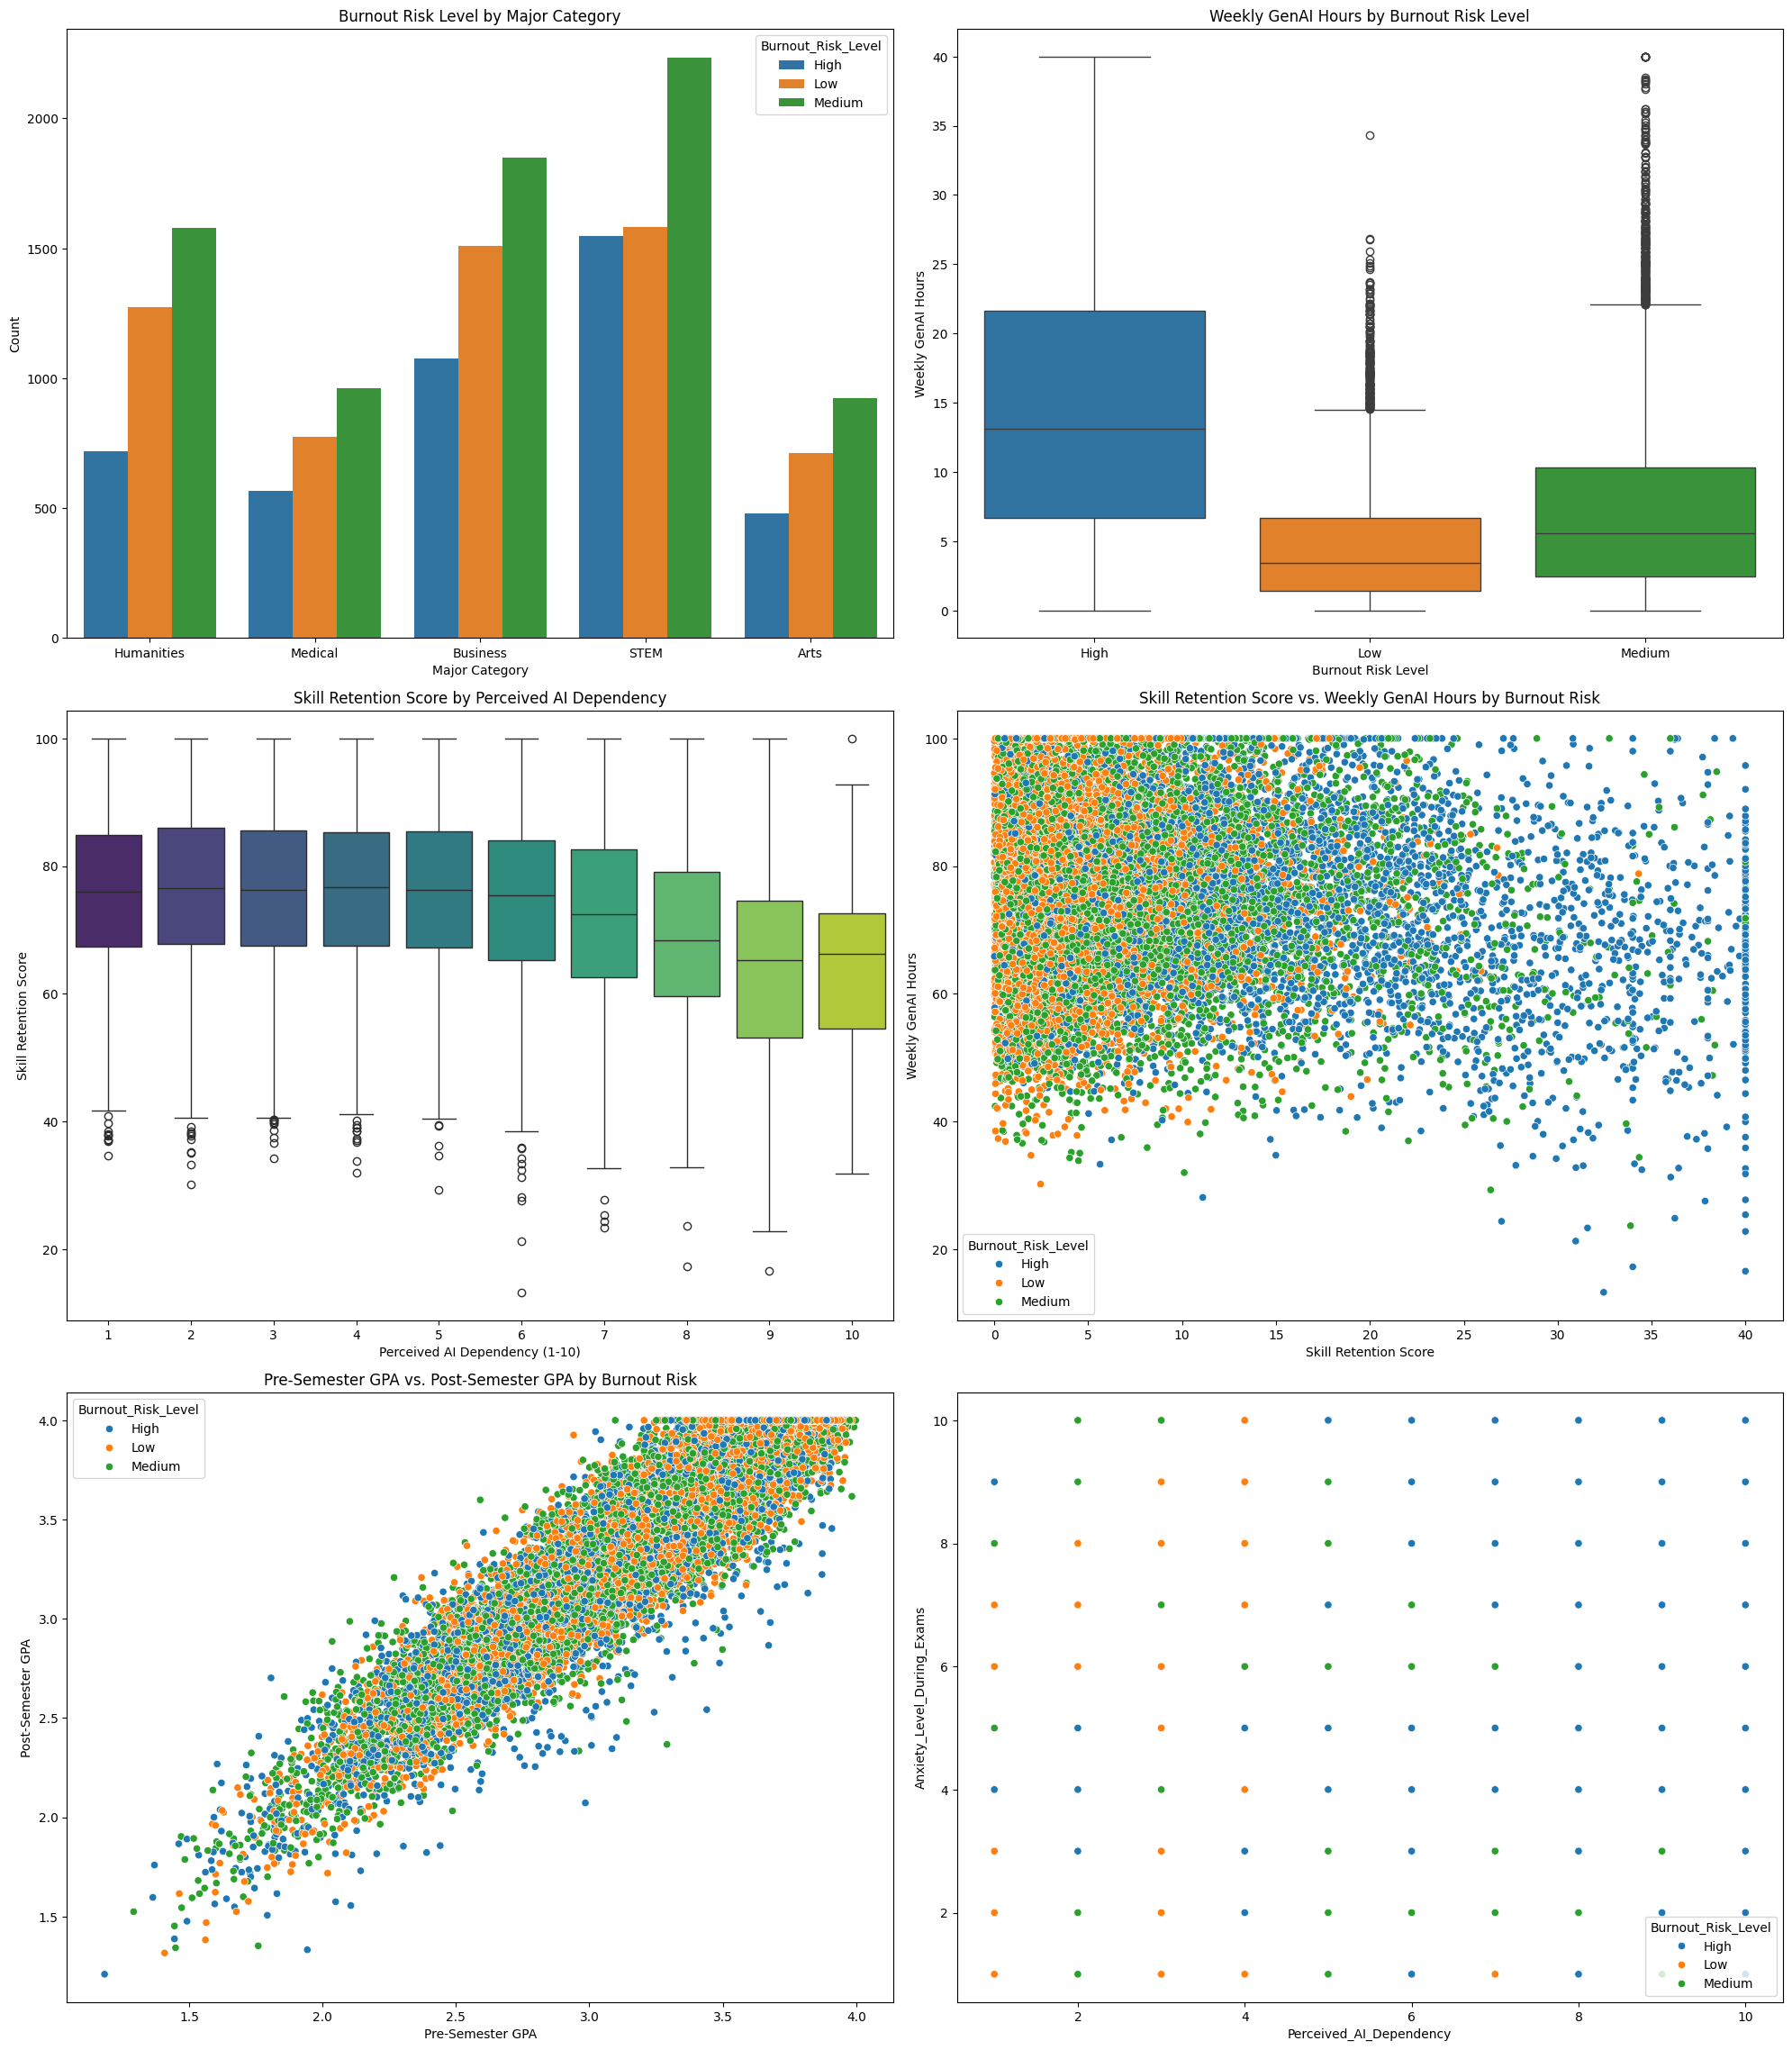

In [35]:
plt.figure(figsize=(20,30))
plt.subplot(4,2,1)
sns.countplot(data=df, x='Major_Category', hue='Burnout_Risk_Level')
plt.title('Burnout Risk Level by Major Category')
plt.xlabel('Major Category')
plt.ylabel('Count')
plt.subplot(4,2,2)
sns.boxplot(data=df, x='Burnout_Risk_Level', y='Weekly_GenAI_Hours', hue='Burnout_Risk_Level', legend=False)
plt.title('Weekly GenAI Hours by Burnout Risk Level')
plt.xlabel('Burnout Risk Level')
plt.ylabel('Weekly GenAI Hours')
plt.subplot(4,2,3)
sns.boxplot(data=df, x='Perceived_AI_Dependency', y='Skill_Retention_Score', palette='viridis')
plt.title('Skill Retention Score by Perceived AI Dependency')
plt.xlabel('Perceived AI Dependency (1-10)')
plt.ylabel('Skill Retention Score')
plt.subplot(4,2,4)
sns.scatterplot(data=df,y='Skill_Retention_Score',x='Weekly_GenAI_Hours',hue='Burnout_Risk_Level')
plt.title('Skill Retention Score vs. Weekly GenAI Hours by Burnout Risk')
plt.xlabel('Skill Retention Score')
plt.ylabel('Weekly GenAI Hours')
plt.subplot(4,2,5)
sns.scatterplot(data=df,x='Pre_Semester_GPA',y='Post_Semester_GPA',hue='Burnout_Risk_Level')
plt.title('Pre-Semester GPA vs. Post-Semester GPA by Burnout Risk')
plt.xlabel('Pre-Semester GPA')
plt.ylabel('Post-Semester GPA')
plt.subplot(4,2,6)
sns.scatterplot(data=df, x='Perceived_AI_Dependency', y='Anxiety_Level_During_Exams',hue='Burnout_Risk_Level')
plt.tight_layout()


# **Train Test Split**

In [40]:
x = ['Pre_Semester_GPA','Weekly_GenAI_Hours','Prompt_Engineering_Skill','Tool_Diversity','Paid_Subscription','Traditional_Study_Hours','Perceived_AI_Dependency','Institutional_Policy','Anxiety_Level_During_Exams','Skill_Retention_Score']
y = ['Post_Semester_GPA']

In [42]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder

In [41]:
x_train,x_test,y_train,y_test = train_test_split(df[x],df[y],test_size=0.2,random_state=42)

In [47]:
ohe = ['Paid_Subscription','Institutional_Policy']
prompt_skills = [['Beginner', 'Intermediate', 'Advanced']]
std = ['Pre_Semester_GPA','Weekly_GenAI_Hours','Tool_Diversity','Traditional_Study_Hours','Perceived_AI_Dependency','Anxiety_Level_During_Exams','Skill_Retention_Score']

tnf = ColumnTransformer([
    ('ohe',OneHotEncoder(sparse_output=False,drop='first'),ohe),
    ('ordinal',OrdinalEncoder(categories=prompt_skills),['Prompt_Engineering_Skill']),
    ('std',StandardScaler(),std)

],remainder='passthrough')

In [48]:
x_train_transformed = tnf.fit_transform(x_train)
x_test_transformed = tnf.transform(x_test)

In [50]:
!pip install xgboost

In [51]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.ensemble import AdaBoostRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [74]:
lr = LinearRegression()
dt = DecisionTreeRegressor()
rf = RandomForestRegressor(max_depth=10, random_state=42, min_samples_split=10, min_samples_leaf=5)
xgb = XGBRegressor()
ada = AdaBoostRegressor()
gb = GradientBoostingRegressor()
svr = SVR()

In [75]:
for model in [lr, dt, rf, xgb, ada, gb, svr]:
    model.fit(x_train_transformed, y_train.values.ravel())
    y_pred = model.predict(x_test_transformed)

    print(type(model).__name__)
    print(f"R2 Score: {r2_score(y_test, y_pred)}")

LinearRegression
R2 Score: 0.879967706320802
DecisionTreeRegressor
R2 Score: 0.7826495837484413
RandomForestRegressor
R2 Score: 0.8819220934280569
XGBRegressor
R2 Score: 0.8770143985748291
AdaBoostRegressor
R2 Score: 0.8299732710878829
GradientBoostingRegressor
R2 Score: 0.8869208599084748
SVR
R2 Score: 0.8805480244569452


In [76]:
from sklearn.ensemble import VotingRegressor

In [77]:
best_voting = VotingRegressor(estimators=[('gb', gb),('svr', svr),('rf',rf),('xgb',xgb)], weights=[5, 3, 2, 1], n_jobs=-1)
best_voting.fit(x_train_transformed, y_train.values.ravel())
y_pred = best_voting.predict(x_test_transformed)
r2_score(y_test, y_pred)

0.8869411227732509

In [61]:
from sklearn.ensemble import BaggingRegressor

In [63]:
bagging = BaggingRegressor(n_estimators=100, random_state=42, n_jobs=-1)
bagging.fit(x_train_transformed, y_train.values.ravel())
y_pred = bagging.predict(x_test_transformed)
r2_score(y_test, y_pred)

0.8789406280087969

In [78]:
from sklearn.pipeline import make_pipeline

In [79]:
final_pipeline = make_pipeline(tnf, best_voting)

final_pipeline.fit(x_train, y_train.values.ravel())

y_pred_final = final_pipeline.predict(x_test)
print(f"Pipeline Test R2 Score: {r2_score(y_test, y_pred_final)}")

Pipeline Test R2 Score: 0.8869415871545074


In [80]:
import pickle

In [81]:
with open('gpa_predictor_pipeline.pkl', 'wb') as file:
    pickle.dump(final_pipeline, file)